# Importing all Important Libraries.

In [24]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt 
from sklearn.impute import SimpleImputer

In [25]:
data = pd.read_csv("loan_approval_data.csv")
data.head()

,Applicant_ID,Applicant_Income,Coapplicant_Income,Employment_Status,Age,Marital_Status,Dependents,Credit_Score,Existing_Loans,DTI_Ratio,Savings,Collateral_Value,Loan_Amount,Loan_Term,Loan_Purpose,Property_Area,Education_Level,Gender,Employer_Category,Loan_Approved
0,1.0,17795.0,1387.0,Salaried,51.0,Married,0.0,637.0,4.0,0.53,19403.0,45638.0,16619.0,84.0,Personal,Urban,Not Graduate,Female,Private,No
1,2.0,2860.0,2679.0,Salaried,46.0,Married,3.0,621.0,2.0,0.30,2580.0,49272.0,38687.0,NaN,Car,Semiurban,Graduate,NaN,Private,No
2,3.0,7390.0,2106.0,Salaried,25.0,Single,2.0,674.0,4.0,0.20,13844.0,6908.0,27943.0,72.0,NaN,Urban,NaN,Female,Government,Yes
3,4.0,13964.0,8173.0,Salaried,40.0,Married,2.0,579.0,3.0,0.31,9553.0,10844.0,27819.0,60.0,Business,Rural,Graduate,Female,Government,No
4,5.0,13284.0,4223.0,Self-employed,31.0,Single,2.0,721.0,1.0,0.29,9386.0,37629.0,12741.0,72.0,Car,NaN,Graduate,Male,Private,Yes


In [26]:
data.info()
data.describe()
data.isnull().sum()

<class 'pandas.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 20 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   Applicant_ID        950 non-null    float64
 1   Applicant_Income    950 non-null    float64
 2   Coapplicant_Income  950 non-null    float64
 3   Employment_Status   950 non-null    str    
 4   Age                 950 non-null    float64
 5   Marital_Status      950 non-null    str    
 6   Dependents          950 non-null    float64
 7   Credit_Score        950 non-null    float64
 8   Existing_Loans      950 non-null    float64
 9   DTI_Ratio           950 non-null    float64
 10  Savings             950 non-null    float64
 11  Collateral_Value    950 non-null    float64
 12  Loan_Amount         950 non-null    float64
 13  Loan_Term           950 non-null    float64
 14  Loan_Purpose        950 non-null    str    
 15  Property_Area       950 non-null    str    
 16  Education_Level   

Applicant_ID          50
Applicant_Income      50
Coapplicant_Income    50
Employment_Status     50
Age                   50
Marital_Status        50
Dependents            50
Credit_Score          50
Existing_Loans        50
DTI_Ratio             50
Savings               50
Collateral_Value      50
Loan_Amount           50
Loan_Term             50
Loan_Purpose          50
Property_Area         50
Education_Level       50
Gender                50
Employer_Category     50
Loan_Approved         50
dtype: int64

# Handling Missing Values

The dataset contains missing values. I first inspect their distribution here.
For model training, imputation is performed later inside a Scikit-learn
pipeline. This is important because the imputer must learn replacement values
from the training data only, not from the complete dataset.

In [27]:
# Inspect missing values without imputing the full dataset
categorical_cols = data.select_dtypes(include=["str","object"]).columns
numerical_cols = data.select_dtypes(include=["number"]).columns

# Handle numerical columns
num_imp = SimpleImputer(strategy="mean")
data[numerical_cols] = num_imp.fit_transform(data[numerical_cols])

# Handle categorical columns
cat_imp = SimpleImputer(strategy="most_frequent")
data[categorical_cols] = cat_imp.fit_transform(data[categorical_cols])

# data.isnull().sum()
data.head()

,Applicant_ID,Applicant_Income,Coapplicant_Income,Employment_Status,Age,Marital_Status,Dependents,Credit_Score,Existing_Loans,DTI_Ratio,Savings,Collateral_Value,Loan_Amount,Loan_Term,Loan_Purpose,Property_Area,Education_Level,Gender,Employer_Category,Loan_Approved
0,1.0,17795.0,1387.0,Salaried,51.0,Married,0.0,637.0,4.0,0.53,19403.0,45638.0,16619.0,84.0,Personal,Urban,Not Graduate,Female,Private,No
1,2.0,2860.0,2679.0,Salaried,46.0,Married,3.0,621.0,2.0,0.30,2580.0,49272.0,38687.0,48.0,Car,Semiurban,Graduate,Male,Private,No
2,3.0,7390.0,2106.0,Salaried,25.0,Single,2.0,674.0,4.0,0.20,13844.0,6908.0,27943.0,72.0,Business,Urban,Graduate,Female,Government,Yes
3,4.0,13964.0,8173.0,Salaried,40.0,Married,2.0,579.0,3.0,0.31,9553.0,10844.0,27819.0,60.0,Business,Rural,Graduate,Female,Government,No
4,5.0,13284.0,4223.0,Self-employed,31.0,Single,2.0,721.0,1.0,0.29,9386.0,37629.0,12741.0,72.0,Car,Urban,Graduate,Male,Private,Yes


# EDA - exploratory data analysis

Text(0.5, 1.0, 'Is Loan approved or not?')

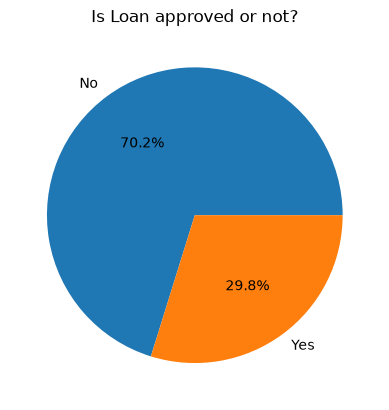

In [28]:
# how balanced our classes are?

classes_count = data["Loan_Approved"].value_counts()

plt.pie(classes_count, labels=["No", "Yes"], autopct="%1.1f%%")
plt.title("Is Loan approved or not?")

[Text(0, 0, '621'), Text(0, 0, '379')]

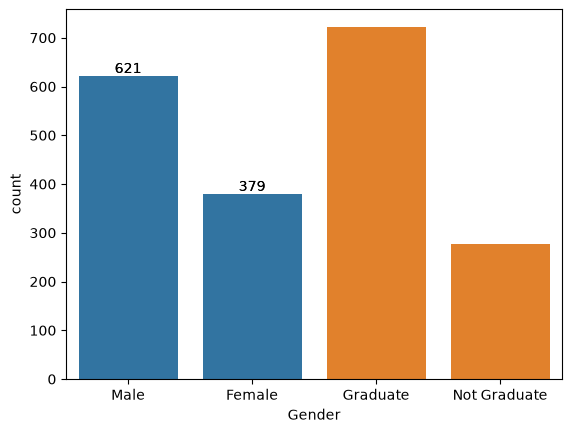

In [29]:
# analyze categories

gender_cnt = data["Gender"].value_counts()
ax = sns.barplot(gender_cnt)
ax.bar_label(ax.containers[0])

edu_cnt = data["Education_Level"].value_counts()
ax = sns.barplot(edu_cnt)
ax.bar_label(ax.containers[0])

<Axes: xlabel='Applicant_Income', ylabel='Count'>

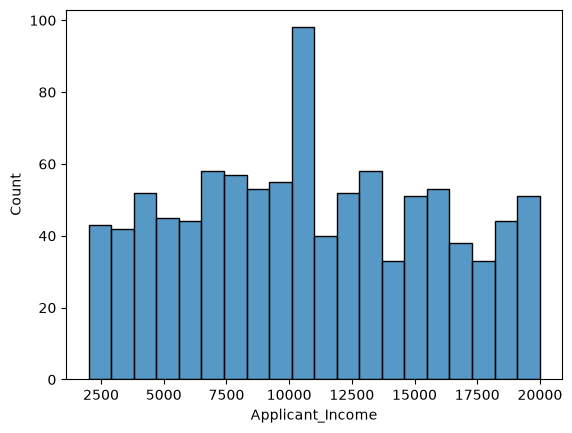

In [30]:
# analyze income

sns.histplot(
    data = data,
    x = "Applicant_Income",
    bins=20
)

<Axes: xlabel='Coapplicant_Income', ylabel='Count'>

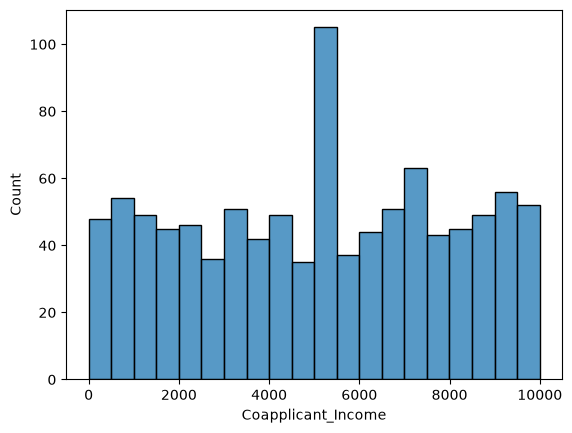

In [31]:
sns.histplot(
    data = data,
    x = "Coapplicant_Income",
    bins=20
)

# Outliers

<Axes: xlabel='Loan_Approved', ylabel='Applicant_Income'>

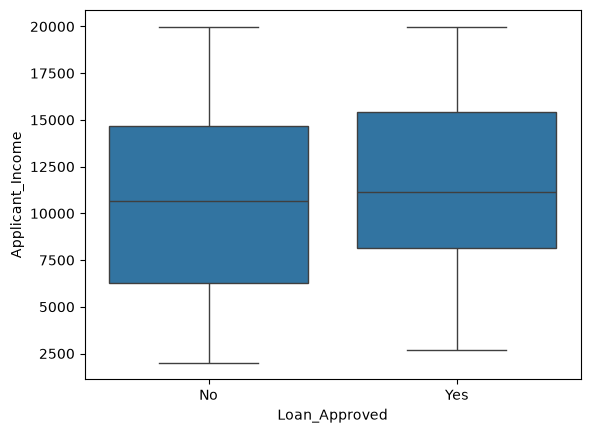

In [32]:
sns.boxplot(
    data = data,
    x = "Loan_Approved",
    y = "Applicant_Income"
    
)

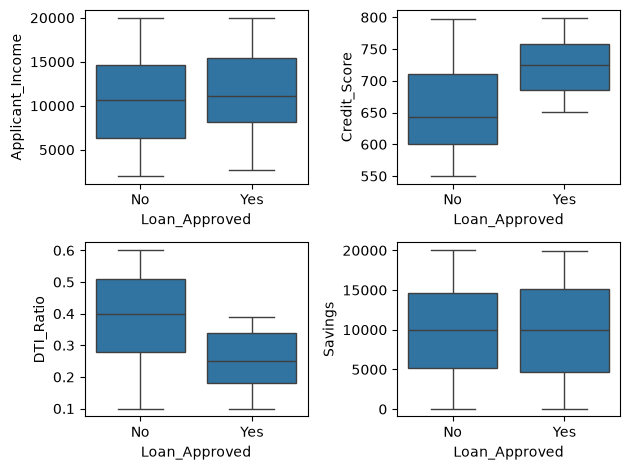

In [33]:
fig, axes = plt.subplots(2, 2)

sns.boxplot(ax=axes[0, 0], data=data, x="Loan_Approved",y="Applicant_Income")
sns.boxplot(ax=axes[0, 1], data=data, x="Loan_Approved",y="Credit_Score")
sns.boxplot(ax=axes[1, 0], data=data, x="Loan_Approved",y="DTI_Ratio")
sns.boxplot(ax=axes[1, 1], data=data, x="Loan_Approved",y="Savings")

plt.tight_layout()

<Axes: xlabel='Credit_Score', ylabel='Count'>

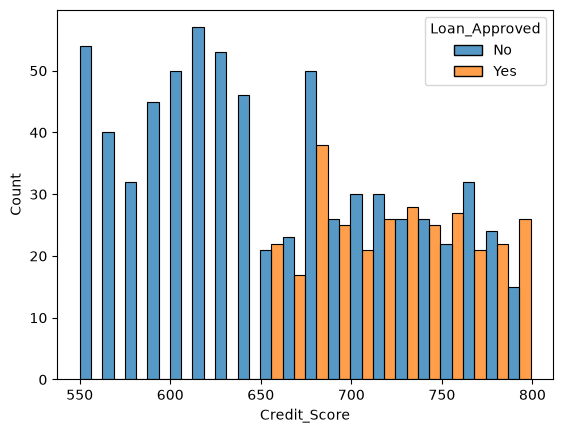

In [34]:
# Credit Score with Loan Approved

sns.histplot(
    data=data,
    x="Credit_Score",
    hue="Loan_Approved",
    bins=20,
    multiple="dodge"
)

<Axes: xlabel='Applicant_Income', ylabel='Count'>

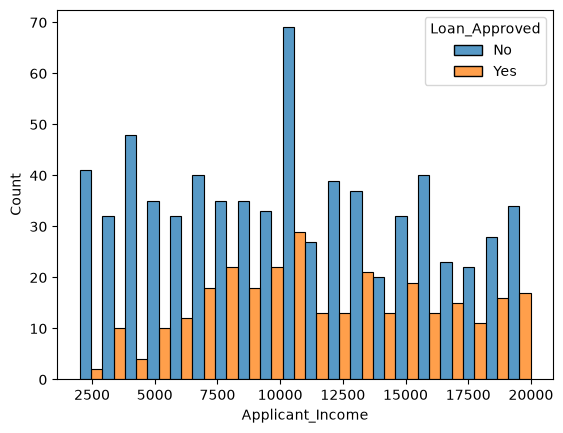

In [35]:
sns.histplot(
    data=data,
    x="Applicant_Income",
    hue="Loan_Approved",
    bins=20,
    multiple="dodge"
)

### Correlation HeatMap
It is a visual representation of the relationships between numerical variables in a dataset.
It shows Correlation coefficient (r) between two numeric variables.
Ranges from -1 to 1.
1 is perfect positive correlation.
-1 is perfect negative correlation.
0 is no linear correlation.

<Axes: >

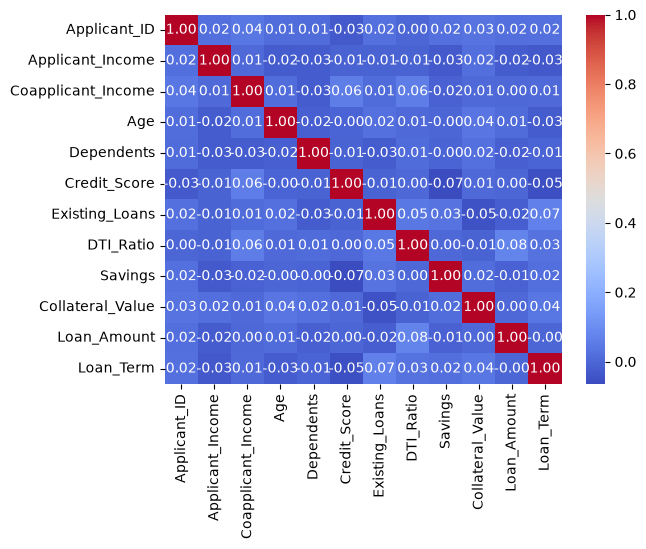

In [36]:
num_cols = data.select_dtypes(include = "number")
corr_matrix = num_cols.corr()
sns.heatmap(
    corr_matrix,
    annot = True,
    fmt = ".2f",
    cmap = "coolwarm"
)

In [37]:
num_cols.corr()["Loan_Approved"].sort_values(ascending = False)

KeyError: 'Loan_Approved'

# Machine Learning Workflow

In this section, I prepare the data for classification, build reusable
preprocessing pipelines, train multiple algorithms, and compare their
performance. The test set is kept separate until final evaluation.

### 1. Prepare Features and Target

Applicant_ID is an identifier and is not used as a predictive feature.
Loan_Approved is the target variable that the models will learn to predict.

In [15]:
from sklearn.preprocessing import LabelEncoder

# Work from the original, unmodified dataset
model_data = data.copy()

# Separate input features and target
X = model_data.drop(columns=["Applicant_ID", "Loan_Approved"])
y_text = model_data["Loan_Approved"].astype(str).str.strip()

# Encode the target labels (for example, No/Yes -> 0/1)
target_encoder = LabelEncoder()
y = target_encoder.fit_transform(y_text)

print("Target classes:", list(target_encoder.classes_))
print("Feature shape:", X.shape)
print("Target distribution:")
display(pd.Series(y_text).value_counts())

Target classes: ['No', 'Yes', nan]
Feature shape: (1000, 18)
Target distribution:


Loan_Approved
No     652
Yes    298
Name: count, dtype: int64

### 2. Train-Test Split
I split the data into training and testing sets using an 80:20 ratio.
Stratification preserves the target-class proportions in both sets.
The test set is reserved for evaluating models on unseen observations.

In [16]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training samples:", len(X_train))
print("Testing samples:", len(X_test))

Training samples: 800
Testing samples: 200


### 3. Preprocessing Pipeline
Numerical and categorical features require different preprocessing.
- Numerical features: median imputation followed by standardization.
- Categorical features: most-frequent imputation followed by one-hot encoding.
- ColumnTransformer applies the appropriate steps to each column group.
- Pipeline keeps preprocessing and model training together.

In [17]:
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.pipeline import Pipeline

# Identify column types from the feature data
numerical_cols = X.select_dtypes(include=np.number).columns.tolist()
categorical_cols = X.select_dtypes(exclude=np.number).columns.tolist()

# Numerical preprocessing
numerical_pipeline = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

# Categorical preprocessing
categorical_pipeline = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

# Combine transformations
preprocessor = ColumnTransformer(transformers=[
    ("numerical", numerical_pipeline, numerical_cols),
    ("categorical", categorical_pipeline, categorical_cols)
])

print("Numerical features:", numerical_cols)
print("Categorical features:", categorical_cols)
print("Preprocessing pipeline created.")

Numerical features: ['Applicant_Income', 'Coapplicant_Income', 'Age', 'Dependents', 'Credit_Score', 'Existing_Loans', 'DTI_Ratio', 'Savings', 'Collateral_Value', 'Loan_Amount', 'Loan_Term']
Categorical features: ['Employment_Status', 'Marital_Status', 'Loan_Purpose', 'Property_Area', 'Education_Level', 'Gender', 'Employer_Category']
Preprocessing pipeline created.


### 4. Train Classification Models
I compare three supervised classification algorithms:
1. Logistic Regression – a linear classification algorithm.
2. K-Nearest Neighbors (KNN) – predicts using the nearest training observations.
3. Gaussian Naive Bayes – applies Bayes' theorem with a conditional-independence assumption.

In [20]:
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.naive_bayes import GaussianNB

from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    confusion_matrix, classification_report
)

models = {
    "Logistic Regression": LogisticRegression(max_iter=1000),
    "KNN": KNeighborsClassifier(n_neighbors=5),
    "Gaussian Naive Bayes": GaussianNB()
}

trained_models = {}
baseline_results = []

for model_name, estimator in models.items():
    model_pipeline = Pipeline(steps=[
        ("preprocessing", preprocessor),
        ("classifier", estimator)
    ])

    model_pipeline.fit(X_train, y_train)
    predictions = model_pipeline.predict(X_test)

    trained_models[model_name] = model_pipeline

    
    baseline_results.append({
        "Model": model_name,
        "Accuracy": accuracy_score(y_test, predictions),
        "Precision": precision_score(
            y_test, predictions, average="weighted", zero_division=0
        ),
        "Recall": recall_score(
            y_test, predictions, average="weighted", zero_division=0
        ),
        "F1 Score": f1_score(
            y_test, predictions, average="weighted", zero_division=0
        )
    })


    print("\n" + "=" * 55)
    print(model_name)
    print("=" * 55)
    print(classification_report(
        y_test, predictions,
        target_names=[str(c) for c in target_encoder.classes_],
        zero_division=0
    ))
    print("Confusion Matrix:\n", confusion_matrix(y_test, predictions))

baseline_results_df = pd.DataFrame(baseline_results).sort_values(
    by="F1 Score", ascending=False
)
display(baseline_results_df)


Logistic Regression
              precision    recall  f1-score   support

          No       0.84      0.93      0.88       130
         Yes       0.82      0.77      0.79        60
         nan       0.00      0.00      0.00        10

    accuracy                           0.83       200
   macro avg       0.55      0.57      0.56       200
weighted avg       0.79      0.83      0.81       200

Confusion Matrix:
 [[121   9   0]
 [ 14  46   0]
 [  9   1   0]]

KNN
              precision    recall  f1-score   support

          No       0.78      0.88      0.83       130
         Yes       0.69      0.60      0.64        60
         nan       0.00      0.00      0.00        10

    accuracy                           0.76       200
   macro avg       0.49      0.49      0.49       200
weighted avg       0.71      0.76      0.73       200

Confusion Matrix:
 [[115  15   0]
 [ 24  36   0]
 [  9   1   0]]

Gaussian Naive Bayes
              precision    recall  f1-score   support

     

,Model,Accuracy,Precision,Recall,F1 Score
0,Logistic Regression,0.835,0.792609,0.835,0.812019
2,Gaussian Naive Bayes,0.775,0.789675,0.775,0.778512
1,KNN,0.755,0.712760,0.755,0.730627


### 5. Visualize Model Performance
I compare accuracy and F1-score visually. Accuracy gives the overall
proportion of correct predictions, while F1-score balances precision and
recall for the selected positive class.

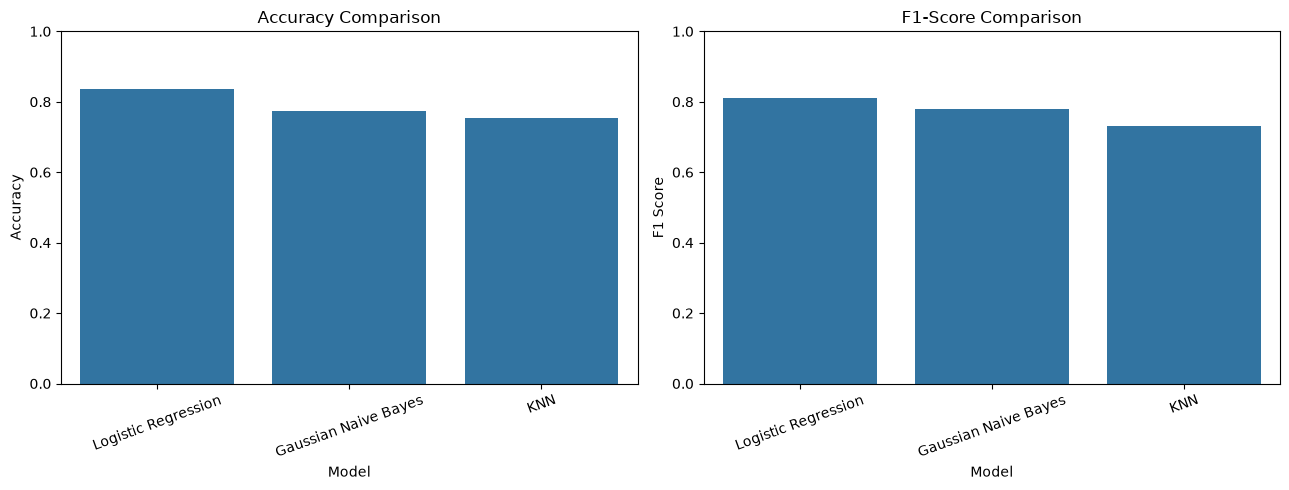

In [21]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

sns.barplot(data=baseline_results_df, x="Model", y="Accuracy", ax=axes[0])
axes[0].set_title("Accuracy Comparison")
axes[0].set_ylim(0, 1)
axes[0].tick_params(axis="x", rotation=20)

sns.barplot(data=baseline_results_df, x="Model", y="F1 Score", ax=axes[1])
axes[1].set_title("F1-Score Comparison")
axes[1].set_ylim(0, 1)
axes[1].tick_params(axis="x", rotation=20)

plt.tight_layout()
plt.show()

### 6. Feature Engineering
Feature engineering creates or transforms input variables to represent
patterns that a model may not capture easily from the original features.

In this experiment, I retain the original variables and add:
- Squared DTI Ratio.
- Squared Credit Score.
- Log-transformed Applicant Income.
I then compare the engineered-feature models with the baseline models using
the same train-test split. Feature engineering is an experiment; it does not
guarantee better performance.

In [39]:
# Create engineered features from the original input features
X_engineered = X.copy()

required_features = [
    "DTI_Ratio", "Credit_Score", "Applicant_Income"
]
missing_required = [col for col in required_features if col not in X_engineered.columns]

if missing_required:
    raise KeyError(f"Expected feature columns are missing: {missing_required}")

X_engineered["DTI_Ratio_sq"] = X_engineered["DTI_Ratio"] ** 2
X_engineered["Credit_Score_sq"] = X_engineered["Credit_Score"] ** 2
X_engineered["Applicant_Income_log"] = np.log1p(
    X_engineered["Applicant_Income"].clip(lower=0)
)

X_train_eng, X_test_eng, y_train_eng, y_test_eng = train_test_split(
    X_engineered, y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

num_cols_eng = X_engineered.select_dtypes(include=np.number).columns.tolist()
cat_cols_eng = X_engineered.select_dtypes(exclude=np.number).columns.tolist()

preprocessor_eng = ColumnTransformer(transformers=[
    ("numerical", Pipeline(steps=[
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler())
    ]), num_cols_eng),
    ("categorical", Pipeline(steps=[
        ("imputer", SimpleImputer(strategy="most_frequent")),
        ("encoder", OneHotEncoder(handle_unknown="ignore"))
    ]), cat_cols_eng)
])

engineered_results = []
engineered_models = {}

for model_name, estimator in models.items():
    engineered_pipeline = Pipeline(steps=[
        ("preprocessing", preprocessor_eng),
        ("classifier", estimator)
    ])

    engineered_pipeline.fit(X_train_eng, y_train_eng)
    predictions = engineered_pipeline.predict(X_test_eng)
    engineered_models[model_name] = engineered_pipeline

    engineered_results.append({
        "Model": model_name,
        "Accuracy": accuracy_score(y_test, predictions),
        "Precision": precision_score(
            y_test, predictions, average="weighted", zero_division=0
        ),
        "Recall": recall_score(
            y_test, predictions, average="weighted", zero_division=0
        ),
        "F1 Score": f1_score(
            y_test, predictions, average="weighted", zero_division=0
        )
    })

engineered_results_df = pd.DataFrame(engineered_results).sort_values(
    by="F1 Score", ascending=False
)
display(engineered_results_df)

,Model,Accuracy,Precision,Recall,F1 Score
0,Logistic Regression,0.860,0.816865,0.860,0.836597
1,KNN,0.845,0.802135,0.845,0.822901
2,Gaussian Naive Bayes,0.800,0.807931,0.800,0.803898


### 7. Compare Original and Engineered Features
This comparison helps me check whether the additional features improve,
reduce, or leave model performance unchanged. I use the F1-score alongside
accuracy rather than selecting a model using accuracy alone.

In [40]:
feature_comparison = baseline_results_df.merge(
    engineered_results_df,
    on="Model",
    suffixes=("_Original", "_Engineered")
)

display(feature_comparison[[
    "Model",
    "Accuracy_Original", "Accuracy_Engineered",
    "F1 Score_Original", "F1 Score_Engineered"
]])

,Model,Accuracy_Original,Accuracy_Engineered,F1 Score_Original,F1 Score_Engineered
0,Logistic Regression,0.835,0.860,0.812019,0.836597
1,Gaussian Naive Bayes,0.775,0.800,0.778512,0.803898
2,KNN,0.755,0.845,0.730627,0.822901


# Final Observations
Use the tables and plots generated above to record:
- Which model achieved the highest test F1-score.
- Which model achieved the highest test accuracy.
- Whether cross-validation results support the test-set comparison.
- Whether feature engineering improved each model.
- What the confusion matrices reveal about false approvals and false rejections.
Do not assume that the highest accuracy automatically makes a model the best
choice. The consequences of different prediction errors matter in a loan
approval context.

In [42]:
best_by_f1 = baseline_results_df.iloc[0]
best_by_accuracy = baseline_results_df.sort_values(
    by="Accuracy", ascending=False
).iloc[0]

print(
    f"Highest test F1-score: {best_by_f1['Model']} "
    f"({best_by_f1['F1 Score']:.3f})"
)
print(
    f"Highest test accuracy: {best_by_accuracy['Model']} "
    f"({best_by_accuracy['Accuracy']:.3f})"
)

print("\nFeature engineering comparison:")
display(feature_comparison)

Highest test F1-score: Logistic Regression (0.812)
Highest test accuracy: Logistic Regression (0.835)

Feature engineering comparison:


,Model,Accuracy_Original,Precision_Original,Recall_Original,F1 Score_Original,Accuracy_Engineered,Precision_Engineered,Recall_Engineered,F1 Score_Engineered
0,Logistic Regression,0.835,0.792609,0.835,0.812019,0.860,0.816865,0.860,0.836597
1,Gaussian Naive Bayes,0.775,0.789675,0.775,0.778512,0.800,0.807931,0.800,0.803898
2,KNN,0.755,0.712760,0.755,0.730627,0.845,0.802135,0.845,0.822901


# Conclusion
Through this project, I explored how supervised Machine Learning can be
applied to a loan approval prediction problem. I began by inspecting the
dataset and using Exploratory Data Analysis to understand applicant and
financial attributes, their distributions, and their relationships with the
target variable.

I then prepared the data for modelling by separating the input features from
the target, removing the applicant identifier, handling missing values,
encoding categorical variables, and scaling numerical features. I used a
train-test split and built preprocessing pipelines so that the preprocessing
steps were learned from training data rather than from the complete dataset.
This helped me understand and avoid data leakage.

I trained and compared Logistic Regression, K-Nearest Neighbors, and Gaussian
Naive Bayes. I evaluated them using accuracy, precision, recall, F1-score,
confusion matrices, cross-validation, and ROC-AUC. I also experimented with
feature engineering by adding squared DTI and credit-score features and a
log-transformed income feature. Comparing the original and engineered
features helped me see that feature transformations can affect algorithms
differently and do not always improve performance.

The most valuable learning from this project was understanding the complete
Machine Learning workflow: exploring data, preparing features, selecting
algorithms, training models, evaluating errors, and interpreting results.
I also learned that model selection should not depend on accuracy alone,
particularly for a sensitive problem such as loan approval.

# Limitations and Future Scope
This project is an educational experiment using a limited dataset. Its
predictions should not be used as the sole basis for real loan decisions.
The dataset may not represent all applicants or real lending conditions.
Future work could include hyperparameter tuning, additional algorithms,
larger and more representative datasets, model interpretability, and
fairness analysis.